In [1]:
import numpy as np
import matplotlib.pyplot as plt
from streamobs.surveys import Survey
import streamobs.match_filter as mf
import copy

Example of a notebook for performing a basic calibration of the error model used in the adaptation filter.
Used to determine the values specified in the `_get_default_errors` function in the match_filter.py file.

In [2]:
import iminuit


#####################################################################################
################################### Fit functions ###################################
#####################################################################################

def fit_error_model(magnitude, errors, CI={"baseline_error": 0.002, "exp_pivot": 27.091072029215375 + 2.5, "exp_scale": 1.0904624484538419}):
    """
    Fit the error model to the provided magnitude and error data.
    
    Parameters
    ----------
    magnitude : array-like
        Array of magnitudes.
    errors : array-like
        Corresponding array of photometric errors.
        
    Returns
    -------
    fit_params : dict
        Fitted parameters of the error model.
    """ 
    
    def chi2(baseline_error, exp_pivot, exp_scale):
        model_errors =  mf.error_model(magnitude, baseline_error, exp_pivot, exp_scale)
        return np.nansum(((errors - model_errors) / errors) ** 2)
    
    m = iminuit.Minuit(chi2, baseline_error=CI['baseline_error'], exp_pivot=CI['exp_pivot'], exp_scale=CI['exp_scale'])
    m.migrad()
    
    fit_params = {'baseline_error': m.values['baseline_error'], 'exp_pivot': m.values['exp_pivot'], 'exp_scale': m.values['exp_scale']}
    return fit_params


def get_median_maglim(survey, band='g'):
    """
    Get the median magnitude limit for a given survey and band.
    
    Parameters
    ----------
    survey : Survey
        The survey object.
    band : str
        The photometric band (default is 'g').
        
    Returns
    -------
    median_maglim : float
        Median magnitude limit for the specified band.
    """
    
    maglims = survey.maglim_maps[band].flatten()
    median_maglim = np.nanmedian(maglims)
    
    return median_maglim

# Euclid

In [3]:
euclid_q1 = Survey.load("euclid", release="q1", verbose=False)
euclid_dr1 = Survey.load("euclid", release="dr1", verbose=False)

/Users/pelissier/Documents/Codes/packages/streamobs/streamobs/surveys.py:1291: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  survey.maglim_maps[band] = hp.read_map(full_path, verbose=False)


## Q1

In [4]:
maglim = get_median_maglim(euclid_q1, band='VIS')
mag_test = np.linspace(16, maglim, 100)

err_survey = euclid_q1.get_photo_error(
    "VIS", magnitude=mag_test, maglim=maglim, kind="catalog"
)

CI = {"baseline_error": np.nanmin(err_survey), "exp_pivot": maglim+3, "exp_scale": 1.}
result = fit_error_model(mag_test, err_survey, CI=CI)
print(f"Using CI: {CI}")
print(f"At a median magnitude limit of {maglim:.2f}, the fitted error is {result}")


Using CI: {'baseline_error': np.float64(0.005156189484585268), 'exp_pivot': np.float32(29.2), 'exp_scale': 1.0}
At a median magnitude limit of 26.20, the fitted error is {'baseline_error': 0.00496800329056289, 'exp_pivot': 29.264379595183062, 'exp_scale': 1.2978631011028825}


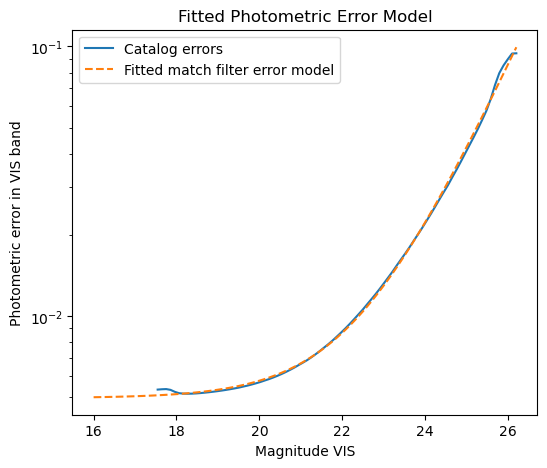

In [5]:
err_results = mf.error_model(
   mag_test, result["baseline_error"], result["exp_pivot"], result["exp_scale"]
)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(mag_test, err_survey, label="Catalog errors")
ax.plot(mag_test, err_results, label="Fitted match filter error model", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("Magnitude VIS")
ax.set_ylabel("Photometric error in VIS band")
ax.set_title("Fitted Photometric Error Model")
ax.legend()
plt.show()



## DR1

Using CI: {'baseline_error': np.float64(0.005156189484585268), 'exp_pivot': np.float32(29.2), 'exp_scale': 1.0}
At a median magnitude limit of 26.20, the fitted error is {'baseline_error': 0.00496800329056289, 'exp_pivot': 29.264379595183062, 'exp_scale': 1.2978631011028825}


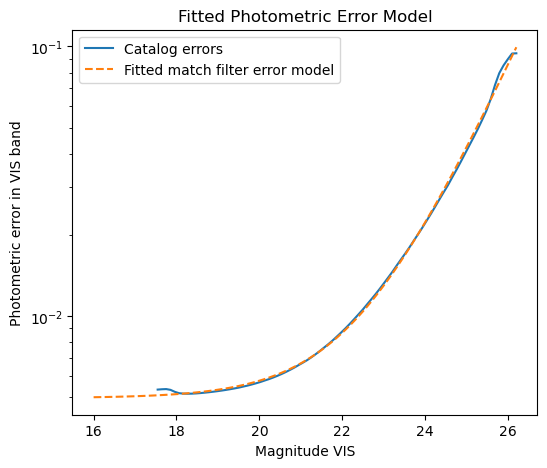

In [6]:
maglim = get_median_maglim(euclid_dr1, band='VIS')
mag_test = np.linspace(16, maglim, 100)

err_survey = euclid_dr1.get_photo_error(
    "VIS", magnitude=mag_test, maglim=maglim, kind="catalog"
)

CI = {"baseline_error": np.nanmin(err_survey), "exp_pivot": maglim+3, "exp_scale": 1.}
result = fit_error_model(mag_test, err_survey, CI=CI)
print(f"Using CI: {CI}")
print(f"At a median magnitude limit of {maglim:.2f}, the fitted error is {result}")

err_results = mf.error_model(
   mag_test, result["baseline_error"], result["exp_pivot"], result["exp_scale"]
)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(mag_test, err_survey, label="Catalog errors")
ax.plot(mag_test, err_results, label="Fitted match filter error model", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("Magnitude VIS")
ax.set_ylabel("Photometric error in VIS band")
ax.set_title("Fitted Photometric Error Model")
ax.legend()
plt.show()



# DES

In [7]:
des_yr6 = Survey.load("des", release="yr6",verbose=False)

Using CI: {'baseline_error': np.float64(0.005029089649369965), 'exp_pivot': np.float32(28.020466), 'exp_scale': 1.0}
At a median magnitude limit of 25.02, the fitted error is {'baseline_error': 0.0048165602901473065, 'exp_pivot': 26.622941095709994, 'exp_scale': 0.9228496000874585}


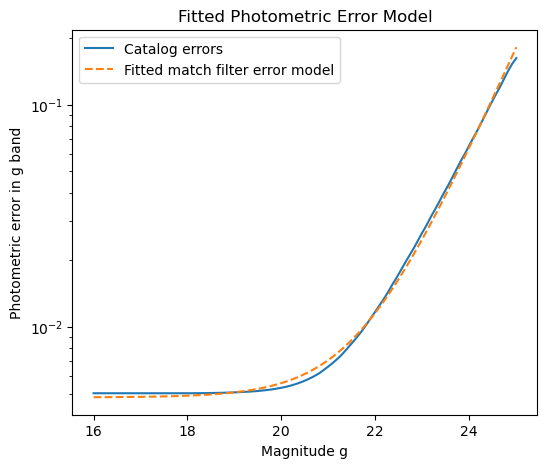

In [8]:
maglim = get_median_maglim(des_yr6, band='g')
mag_test = np.linspace(16, maglim, 100)

err_survey = des_yr6.get_photo_error(
    "g", magnitude=mag_test, maglim=maglim, kind="catalog"
)


CI = {"baseline_error": np.nanmin(err_survey), "exp_pivot": maglim+3, "exp_scale": 1.}
result = fit_error_model(mag_test, err_survey, CI=CI)
print(f"Using CI: {CI}")
print(f"At a median magnitude limit of {maglim:.2f}, the fitted error is {result}")

err_results = mf.error_model(
   mag_test, result["baseline_error"], result["exp_pivot"], result["exp_scale"]
)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(mag_test, err_survey, label="Catalog errors")
ax.plot(mag_test, err_results, label="Fitted match filter error model", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("Magnitude g")
ax.set_ylabel("Photometric error in g band")
ax.set_title("Fitted Photometric Error Model")
ax.legend()
plt.show()



# LSST

## Year 1

In [9]:
lsst_yr1 = Survey.load("lsst", release="yr1",verbose=False)

Using CI: {'baseline_error': np.float64(0.0050028647180608244), 'exp_pivot': np.float64(28.484530455530077), 'exp_scale': 1.0}
At a median magnitude limit of 25.48, the fitted error is {'baseline_error': 0.004800818381447672, 'exp_pivot': 26.880468738326915, 'exp_scale': 0.9450932038257565}


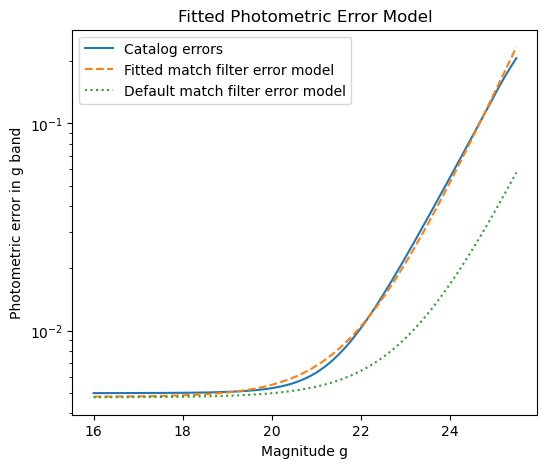

In [10]:
maglim = get_median_maglim(lsst_yr1, band='g')
mag_test = np.linspace(16, maglim, 100)

err_survey = lsst_yr1.get_photo_error(
    "g", magnitude=mag_test, maglim=maglim, kind="catalog"
)


CI = {"baseline_error": np.nanmin(err_survey), "exp_pivot": maglim+3, "exp_scale": 1.}
result = fit_error_model(mag_test, err_survey, CI=CI)
print(f"Using CI: {CI}")
print(f"At a median magnitude limit of {maglim:.2f}, the fitted error is {result}")

err_results = mf.error_model(
   mag_test, result["baseline_error"], result["exp_pivot"], result["exp_scale"]
)
err_defaults = mf.error_model(mag_test) # Errors fitted on KB's paper errors
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(mag_test, err_survey, label="Catalog errors")
ax.plot(mag_test, err_results, label="Fitted match filter error model", linestyle="--")
ax.plot(mag_test, err_defaults, label="Default match filter error model", linestyle=":")
ax.set_yscale("log")
ax.set_xlabel("Magnitude g")
ax.set_ylabel("Photometric error in g band")
ax.set_title("Fitted Photometric Error Model")
ax.legend()
plt.show()



## Year 4

In [11]:
lsst_yr4 = Survey.load("lsst", release="yr4",verbose=False)

Using CI: {'baseline_error': np.float64(0.005001767922515701), 'exp_pivot': np.float64(29.311507891475465), 'exp_scale': 1.0}
At a median magnitude limit of 26.31, the fitted error is {'baseline_error': 0.004832499118223667, 'exp_pivot': 27.702832261572617, 'exp_scale': 0.94286492190896}


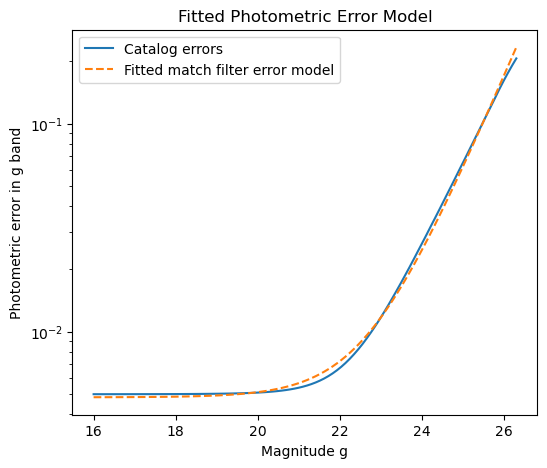

In [12]:
maglim = get_median_maglim(lsst_yr4, band='g')
mag_test = np.linspace(16, maglim, 100)

err_survey = lsst_yr4.get_photo_error(
    "g", magnitude=mag_test, maglim=maglim, kind="catalog"
)


CI = {"baseline_error": np.nanmin(err_survey), "exp_pivot": maglim+3, "exp_scale": 1.}
result = fit_error_model(mag_test, err_survey, CI=CI)
print(f"Using CI: {CI}")
print(f"At a median magnitude limit of {maglim:.2f}, the fitted error is {result}")

err_results = mf.error_model(
   mag_test, result["baseline_error"], result["exp_pivot"], result["exp_scale"]
)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(mag_test, err_survey, label="Catalog errors")
ax.plot(mag_test, err_results, label="Fitted match filter error model", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("Magnitude g")
ax.set_ylabel("Photometric error in g band")
ax.set_title("Fitted Photometric Error Model")
ax.legend()
plt.show()

## Year 5

In [13]:
lsst_yr5 = Survey.load("lsst", release="yr5",verbose=False)

Using CI: {'baseline_error': np.float64(0.005001767922515701), 'exp_pivot': np.float64(29.42663264471519), 'exp_scale': 1.0}
At a median magnitude limit of 26.43, the fitted error is {'baseline_error': 0.00483623259650458, 'exp_pivot': 27.81736043093501, 'exp_scale': 0.9425830473455459}


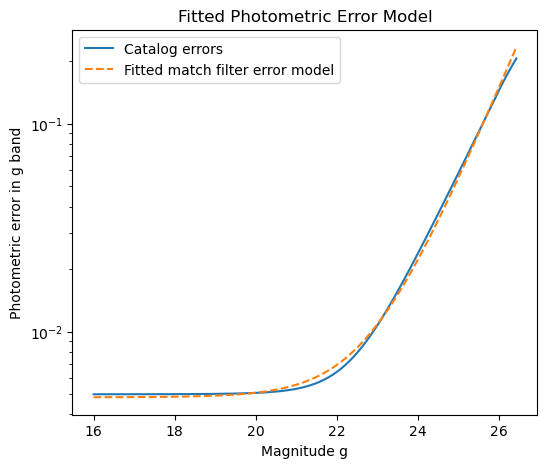

In [14]:
maglim = get_median_maglim(lsst_yr5, band='g')
mag_test = np.linspace(16, maglim, 100)

err_survey = lsst_yr5.get_photo_error(
    "g", magnitude=mag_test, maglim=maglim, kind="catalog"
)


CI = {"baseline_error": np.nanmin(err_survey), "exp_pivot": maglim+3, "exp_scale": 1.}
result = fit_error_model(mag_test, err_survey, CI=CI)
print(f"Using CI: {CI}")
print(f"At a median magnitude limit of {maglim:.2f}, the fitted error is {result}")

err_results = mf.error_model(
   mag_test, result["baseline_error"], result["exp_pivot"], result["exp_scale"]
)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(mag_test, err_survey, label="Catalog errors")
ax.plot(mag_test, err_results, label="Fitted match filter error model", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("Magnitude g")
ax.set_ylabel("Photometric error in g band")
ax.set_title("Fitted Photometric Error Model")
ax.legend()
plt.show()

# Roman

In [15]:
roman_dc2 = Survey.load("roman", release="dc2",verbose=False)

Using CI: {'baseline_error': np.float64(0.005117480456614578), 'exp_pivot': np.float64(29.37158052765188), 'exp_scale': 1.0}
At a median magnitude limit of 26.37, the fitted error is {'baseline_error': 0.004861259453700118, 'exp_pivot': 29.055127840569437, 'exp_scale': 1.3447251265254792}


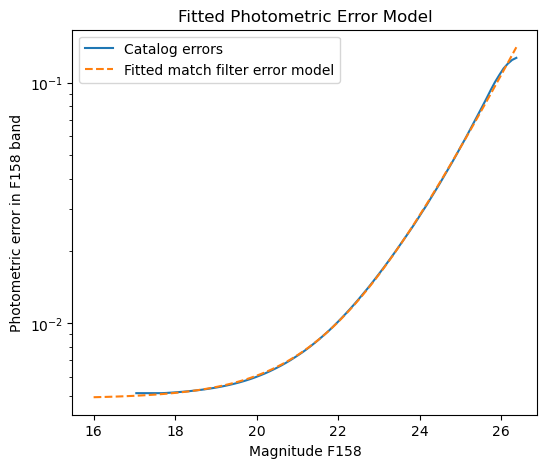

In [16]:
maglim = get_median_maglim(roman_dc2, band='F158')
mag_test = np.linspace(16, maglim, 100)

err_survey = roman_dc2.get_photo_error(
    "F158", magnitude=mag_test, maglim=maglim, kind="catalog"
)


CI = {"baseline_error": np.nanmin(err_survey), "exp_pivot": maglim+3, "exp_scale": 1.}
result = fit_error_model(mag_test, err_survey, CI=CI)
print(f"Using CI: {CI}")
print(f"At a median magnitude limit of {maglim:.2f}, the fitted error is {result}")

err_results = mf.error_model(
   mag_test, result["baseline_error"], result["exp_pivot"], result["exp_scale"]
)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(mag_test, err_survey, label="Catalog errors")
ax.plot(mag_test, err_results, label="Fitted match filter error model", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("Magnitude F158")
ax.set_ylabel("Photometric error in F158 band")
ax.set_title("Fitted Photometric Error Model")
ax.legend()
plt.show()

# Delve

In [17]:
delve_dr3gold = Survey.load("delve", release="dr3_gold",verbose=False)

Using CI: {'baseline_error': np.float64(0.010635078152077749), 'exp_pivot': np.float32(27.352928), 'exp_scale': 1.0}
At a median magnitude limit of 24.35, the fitted error is {'baseline_error': 0.010145299219516157, 'exp_pivot': 25.719668020083876, 'exp_scale': 0.7769367685720466}


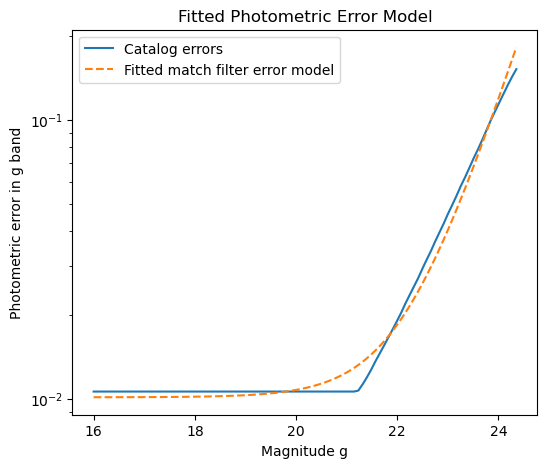

In [18]:
maglim = get_median_maglim(delve_dr3gold, band='g')
mag_test = np.linspace(16, maglim, 100)

err_survey = delve_dr3gold.get_photo_error(
    "g", magnitude=mag_test, maglim=maglim, kind="catalog"
)


CI = {"baseline_error": np.nanmin(err_survey), "exp_pivot": maglim+3, "exp_scale": 1.}
result = fit_error_model(mag_test, err_survey, CI=CI)
print(f"Using CI: {CI}")
print(f"At a median magnitude limit of {maglim:.2f}, the fitted error is {result}")

err_results = mf.error_model(
   mag_test, result["baseline_error"], result["exp_pivot"], result["exp_scale"]
)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(mag_test, err_survey, label="Catalog errors")
ax.plot(mag_test, err_results, label="Fitted match filter error model", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("Magnitude g")
ax.set_ylabel("Photometric error in g band")
ax.set_title("Fitted Photometric Error Model")
ax.legend()
plt.show()

*Note: Delve's errors were estimated to be between 21 and 24 magnitudes; they
were therefore extrapolated using a plateau for lower magnitudes, resulting in a
discontinuous function.*